<a href="https://colab.research.google.com/github/kijan17/UAS_ProbabilitasStatistika/blob/main/Kelompok11_UAS_Statistika.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from google.colab import files

print("Silakan unggah file 3TIA_11_PenggunaSosmed.xlsx")
uploaded = files.upload()
nama_file = list(uploaded.keys())[0]
print(f"\n[BERHASIL] File terbaca: {nama_file}")

Silakan unggah file 3TIA_11_PenggunaSosmed.xlsx


Saving 3TIA_11_PenggunaSosmed.xlsx to 3TIA_11_PenggunaSosmed.xlsx

[BERHASIL] File terbaca: 3TIA_11_PenggunaSosmed.xlsx


#Cell 2: Tahap 1 — Pembersihan Data (Hapus Duplikat) & Pembuatan

In [ ]:
# Membaca data mentah
df_raw = pd.read_excel(nama_file)
print(f"Jumlah baris awal            : {len(df_raw)} baris")

# Hapus baris kosong jika ada
df = df_raw.dropna().copy()

# Hapus duplikat berdasarkan semua kolom KECUALI User_ID
kolom_tanpa_id = [c for c in df.columns if c.lower().replace(' ', '_') != 'user_id']
df_clean = df.drop_duplicates(subset=kolom_tanpa_id).copy()

# Sederhanakan nama kolom waktu penggunaan
if 'Daily_Usage_Time (minutes)' in df_clean.columns:
    df_clean = df_clean.rename(columns={'Daily_Usage_Time (minutes)': 'Daily_Usage_Time'})

# Buat variabel turunan Total_Interaksi
df_clean['Total_Interaksi'] = (
    df_clean['Posts_Per_Day'] +
    df_clean['Likes_Received_Per_Day'] +
    df_clean['Comments_Received_Per_Day'] +
    df_clean['Messages_Sent_Per_Day']
)

print(f"Jumlah data unik (bersih)    : {len(df_clean)} baris")
print(f"Missing value setelah bersih : {int(df_clean.isna().sum().sum())}\n")

print("=== Sebaran Responden Unik per Platform ===")
print(df_clean['Platform'].value_counts())

Jumlah baris awal            : 1000 baris
Jumlah data unik (bersih)    : 200 baris
Missing value setelah bersih : 0

=== Sebaran Responden Unik per Platform ===
Platform
Instagram    50
Twitter      40
Facebook     38
LinkedIn     24
Whatsapp     16
Telegram     16
Snapchat     16
Name: count, dtype: int64


#Cell 3: Tahap 2A — Uji Normalitas Data Mentah (K-S & Shapiro-Wilk)

In [ ]:
alpha = 0.05

print("=== 1. UJI NORMALITAS KESELURUHAN (Kolmogorov-Smirnov, n >= 50) ===")
for var in ['Daily_Usage_Time', 'Total_Interaksi']:
    data = df_clean[var]
    stat_ks, p_ks = stats.kstest(data, 'norm', args=(data.mean(), data.std(ddof=1)))
    status = "Normal (p > 0.05)" if p_ks > alpha else "TIDAK Normal (p <= 0.05)"
    print(f"- {var:17s} | D = {stat_ks:.4f} | p-value = {p_ks:.4f} -> {status}")

print("\n=== 2. UJI NORMALITAS PER PLATFORM (Shapiro-Wilk, n < 50) ===")
for var in ['Daily_Usage_Time', 'Total_Interaksi']:
    print(f"\nVariabel: {var}")
    for platform, grup in df_clean.groupby('Platform'):
        if len(grup) >= 3:
            stat_sw, p_sw = stats.shapiro(grup[var])
            status = "Normal" if p_sw > alpha else "TIDAK Normal"
            print(f"  {platform:10s} (n={len(grup):2d}) | W = {stat_sw:.4f} | p-value = {p_sw:.4f} -> {status}")

=== 1. UJI NORMALITAS KESELURUHAN (Kolmogorov-Smirnov, n >= 50) ===
- Daily_Usage_Time  | D = 0.1507 | p-value = 0.0002 -> TIDAK Normal (p <= 0.05)
- Total_Interaksi   | D = 0.1119 | p-value = 0.0123 -> TIDAK Normal (p <= 0.05)

=== 2. UJI NORMALITAS PER PLATFORM (Shapiro-Wilk, n < 50) ===

Variabel: Daily_Usage_Time
  Facebook   (n=38) | W = 0.9521 | p-value = 0.1044 -> Normal
  Instagram  (n=50) | W = 0.9675 | p-value = 0.1830 -> Normal
  LinkedIn   (n=24) | W = 0.8963 | p-value = 0.0180 -> TIDAK Normal
  Snapchat   (n=16) | W = 0.8822 | p-value = 0.0419 -> TIDAK Normal
  Telegram   (n=16) | W = 0.9312 | p-value = 0.2546 -> Normal
  Twitter    (n=40) | W = 0.8947 | p-value = 0.0013 -> TIDAK Normal
  Whatsapp   (n=16) | W = 0.8723 | p-value = 0.0295 -> TIDAK Normal

Variabel: Total_Interaksi
  Facebook   (n=38) | W = 0.9561 | p-value = 0.1419 -> Normal
  Instagram  (n=50) | W = 0.9806 | p-value = 0.5783 -> Normal
  LinkedIn   (n=24) | W = 0.9750 | p-value = 0.7900 -> Normal
  Snapchat

#Cell 4: Tahap 2B — Uji Homogenitas Varians (Levene's Test)

In [ ]:
print("=== UJI HOMOGENITAS VARIANS ANTAR PLATFORM (Levene's Test) ===")
for var in ['Daily_Usage_Time', 'Total_Interaksi']:
    kelompok = [grup[var].values for _, grup in df_clean.groupby('Platform')]
    stat_lev, p_lev = stats.levene(*kelompok)
    status = "Homogen (p > 0.05)" if p_lev > alpha else "TIDAK Homogen (p <= 0.05)"
    print(f"- {var:17s} | F = {stat_lev:.4f} | p-value = {p_lev:.4f} -> {status}")

=== UJI HOMOGENITAS VARIANS ANTAR PLATFORM (Levene's Test) ===
- Daily_Usage_Time  | F = 8.2963 | p-value = 0.0000 -> TIDAK Homogen (p <= 0.05)
- Total_Interaksi   | F = 4.5575 | p-value = 0.0002 -> TIDAK Homogen (p <= 0.05)


#Cell 5: Tahap 3A — Uji Komparasi (Kruskal-Wallis H + Effect Size + Median & IQR)

In [ ]:
print("=== UJI KOMPARASI NON-PARAMETRIK: KRUSKAL-WALLIS H TEST ===")
print("H0: Tidak terdapat perbedaan signifikan antar 7 platform media sosial.")
print("H1: Terdapat minimal satu platform yang berbeda signifikan.")
print(f"Taraf signifikansi (alpha) = {alpha}\n")

n = len(df_clean)
k = df_clean['Platform'].nunique()

for var in ['Daily_Usage_Time', 'Total_Interaksi']:
    kelompok = [grup[var].values for _, grup in df_clean.groupby('Platform')]
    h_stat, p_val = stats.kruskal(*kelompok)

    # Effect Size Kruskal-Wallis (Epsilon-squared / Eta-squared berbasis H)
    eta2_h = (h_stat - k + 1) / (n - k)
    if eta2_h >= 0.14:
        kat_efek = "Besar (Large)"
    elif eta2_h >= 0.06:
        kat_efek = "Sedang (Medium)"
    else:
        kat_efek = "Kecil (Small)"

    keputusan = "Tolak H0 (Signifikan)" if p_val <= alpha else "Gagal Tolak H0 (Tidak Signifikan)"

    print(f"Variabel: {var}")
    print(f"  Statistik H : {h_stat:.4f}")
    print(f"  p-value     : {p_val:.4e}")
    print(f"  Effect Size (Eta^2_H) : {eta2_h:.4f} -> Efek {kat_efek}")
    print(f"  Keputusan   : {keputusan}\n")

# Ringkasan Median & IQR per Platform (lebih tepat untuk non-parametrik)
print("=== RINGKASAN MEDIAN & IQR PER PLATFORM ===")
ringkasan = df_clean.groupby('Platform').agg(
    n=('Daily_Usage_Time', 'count'),
    Median_Waktu=('Daily_Usage_Time', 'median'),
    IQR_Waktu=('Daily_Usage_Time', lambda s: s.quantile(0.75) - s.quantile(0.25)),
    Median_Interaksi=('Total_Interaksi', 'median'),
    IQR_Interaksi=('Total_Interaksi', lambda s: s.quantile(0.75) - s.quantile(0.25))
).sort_values('Median_Waktu', ascending=False)

display(ringkasan)

=== UJI KOMPARASI NON-PARAMETRIK: KRUSKAL-WALLIS H TEST ===
H0: Tidak terdapat perbedaan signifikan antar 7 platform media sosial.
H1: Terdapat minimal satu platform yang berbeda signifikan.
Taraf signifikansi (alpha) = 0.05

Variabel: Daily_Usage_Time
  Statistik H : 140.0135
  p-value     : 9.9568e-28
  Effect Size (Eta^2_H) : 0.6944 -> Efek Besar (Large)
  Keputusan   : Tolak H0 (Signifikan)

Variabel: Total_Interaksi
  Statistik H : 151.6987
  p-value     : 3.3836e-30
  Effect Size (Eta^2_H) : 0.7549 -> Efek Besar (Large)
  Keputusan   : Tolak H0 (Signifikan)

=== RINGKASAN MEDIAN & IQR PER PLATFORM ===


,n,Median_Waktu,IQR_Waktu,Median_Interaksi,IQR_Interaksi
Platform,,,,,
Instagram,50,150.0,30.00,139.0,30.00
Whatsapp,16,90.0,31.25,74.0,26.00
Snapchat,16,90.0,45.00,63.5,33.75
Twitter,40,85.0,16.25,74.0,23.75
Telegram,16,80.0,15.00,63.0,33.25
Facebook,38,70.0,23.75,48.0,26.25
LinkedIn,24,55.0,6.25,30.0,9.50


#Cell 6: Tahap 3B — Uji Korelasi (Rank Spearman)

In [ ]:
print("=== UJI KORELASI NON-PARAMETRIK: RANK SPEARMAN ===")
print("H0: Tidak terdapat korelasi signifikan antara Daily_Usage_Time dan Total_Interaksi (rho = 0).")
print("H1: Terdapat korelasi signifikan antara Daily_Usage_Time dan Total_Interaksi (rho != 0).")
print(f"Taraf signifikansi (alpha) = {alpha}\n")

rho, p_sp = stats.spearmanr(df_clean['Daily_Usage_Time'], df_clean['Total_Interaksi'])

# Interpretasi kekuatan korelasi (sekaligus Effect Size)
abs_rho = abs(rho)
if abs_rho >= 0.80:
    kekuatan = "Sangat Kuat"
elif abs_rho >= 0.60:
    kekuatan = "Kuat"
elif abs_rho >= 0.40:
    kekuatan = "Sedang"
else:
    kekuatan = "Lemah"

arah = "Positif (searah)" if rho > 0 else "Negatif (berlawanan)"
keputusan_sp = "Tolak H0 (Signifikan)" if p_sp <= alpha else "Gagal Tolak H0 (Tidak Signifikan)"

print(f"Koefisien Spearman (rho) : {rho:.4f}")
print(f"p-value                  : {p_sp:.4e}")
print(f"Arah & Kekuatan (Effect) : {arah}, {kekuatan}")
print(f"Keputusan                : {keputusan_sp}")

=== UJI KORELASI NON-PARAMETRIK: RANK SPEARMAN ===
H0: Tidak terdapat korelasi signifikan antara Daily_Usage_Time dan Total_Interaksi (rho = 0).
H1: Terdapat korelasi signifikan antara Daily_Usage_Time dan Total_Interaksi (rho != 0).
Taraf signifikansi (alpha) = 0.05

Koefisien Spearman (rho) : 0.9266
p-value                  : 4.8294e-86
Arah & Kekuatan (Effect) : Positif (searah), Sangat Kuat
Keputusan                : Tolak H0 (Signifikan)


#Cell 7: Visualisasi Hasil untuk Slide Presentasi UAS

/tmp/ipykernel_465/1519193816.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Platform', y='Daily_Usage_Time', order=urutan_platform, ax=axes[0], palette='viridis')
/tmp/ipykernel_465/1519193816.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Platform', y='Total_Interaksi', order=urutan_platform, ax=axes[1], palette='viridis')


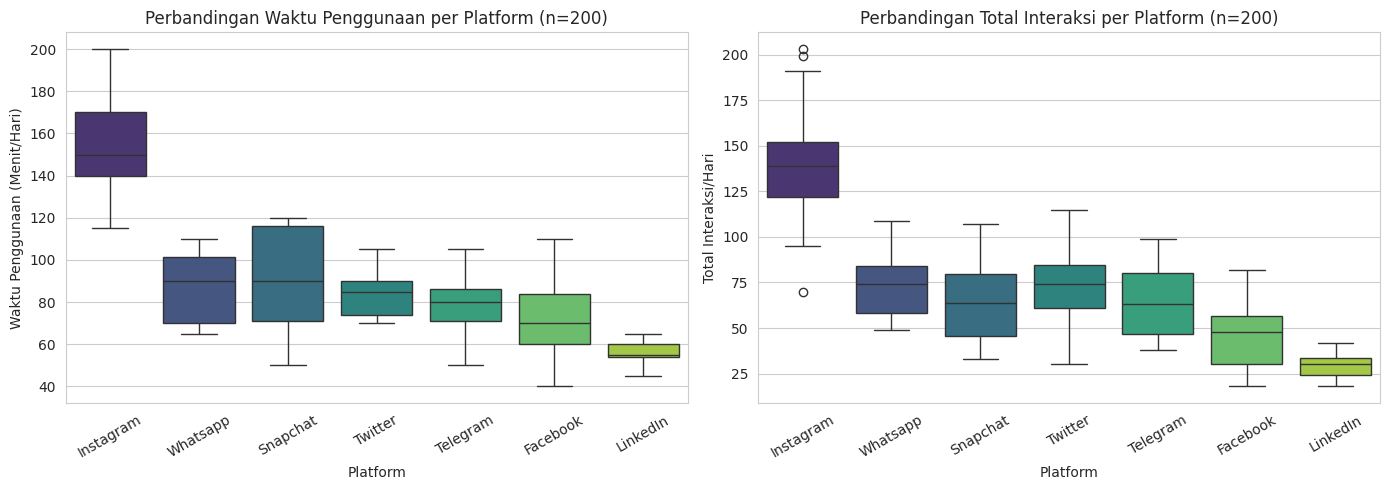

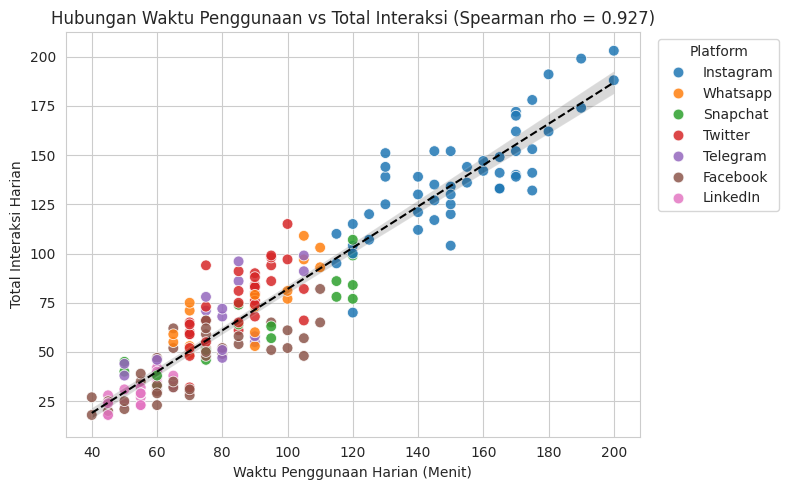

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
urutan_platform = ringkasan.index.tolist()

# Grafik 1: Boxplot Waktu Penggunaan & Total Interaksi per Platform
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_clean, x='Platform', y='Daily_Usage_Time', order=urutan_platform, ax=axes[0], palette='viridis')
axes[0].set_title('Perbandingan Waktu Penggunaan per Platform (n=200)')
axes[0].set_ylabel('Waktu Penggunaan (Menit/Hari)')
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(data=df_clean, x='Platform', y='Total_Interaksi', order=urutan_platform, ax=axes[1], palette='viridis')
axes[1].set_title('Perbandingan Total Interaksi per Platform (n=200)')
axes[1].set_ylabel('Total Interaksi/Hari')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# Grafik 2: Scatter Plot Hubungan Waktu Penggunaan vs Total Interaksi
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='Daily_Usage_Time', y='Total_Interaksi', hue='Platform', hue_order=urutan_platform, s=60, alpha=0.85)
sns.regplot(data=df_clean, x='Daily_Usage_Time', y='Total_Interaksi', scatter=False, color='black', line_kws={'linestyle': '--', 'linewidth': 1.5})
plt.title(f'Hubungan Waktu Penggunaan vs Total Interaksi (Spearman rho = {rho:.3f})')
plt.xlabel('Waktu Penggunaan Harian (Menit)')
plt.ylabel('Total Interaksi Harian')
plt.legend(title='Platform', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()